# Terpene exposure transcriptomics: pilot analysis

**Research question:** Which metabolic and signaling responses to terpene exposure are reproducible, and which depend on cellular context or a specific target?

This notebook documents a first-pass analysis of GEO **GSE136998**, linalool exposure in *Listeria monocytogenes* ATCC 19115. It captures methods and descriptive results as a reproducible notebook. It is a pilot, not a cross-study synthesis or a human-cell/Perturb-seq analysis.

> **Interpretation boundary:** GEO provides an RSEM FPKM expression matrix. The calculations below are descriptive group means and log-ratios only. They are not differential-expression tests, do not provide p-values/FDR, and cannot establish direct targets, pathway causality, enzyme activity, or metabolite flux.

## 1. Study design and provenance

GEO documents the deposited contrast as untreated control versus 8 h linalool at 1× MIC. The paper describes sampling at 4, 8, and 12 h, but GEO's series-level design confirms only the 8 h contrast. GEO sample names identify three control samples (`LM-DZ1`–`LM-DZ3`) and three treated samples (`LM-FZC1`–`LM-FZC3`). Treatment is reported as 0.5% v/v (4.35 mg/mL). At MIC, broad stress and growth inhibition may accompany any specific response.

- GEO: [GSE136998](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE136998)
- Publication: [Gao et al. 2019](https://doi.org/10.3389/fmicb.2019.02947)
- Processed matrix: `GSE136998_rsem.genes.fpkm.table.txt.gz` (downloaded from GEO; checksum recorded in the run manifest)
- GEO matrix contains 2,976 expression rows and six sample columns; feature identifiers are opaque `geneN` / `rnaN` values pending annotation crosswalk.

In [ ]:
from pathlib import Path
import os, urllib.request

if Path('/content').exists():
    candidates = [Path.cwd(), Path('/content/terputer-terpene-exposure'), Path('/content/terpene-transcriptomics')]
    project = next((p for p in candidates if (p / 'results/gse136998/run_manifest.json').exists() and (p / 'data/jiang/sources.json').exists()), None)
    if project is None:
        project = Path('/content/terputer-terpene-exposure')
        site = 'https://terpedia.github.io/research/terpene-transcriptomics/'
        files = ['results/gse136998/GSE136998_rsem.genes.fpkm.table.txt.gz', 'results/gse136998/run_manifest.json', 'data/jiang/sources.json', 'data/jiang/README.md', 'data/jiang/a549_ifnb.parquet', 'data/jiang/a549_ifng.parquet']
        for name in files:
            local = project / name
            local.parent.mkdir(parents=True, exist_ok=True)
            if not local.exists(): urllib.request.urlretrieve(site + name, local)
    (project / 'notebooks').mkdir(exist_ok=True)
    os.chdir(project / 'notebooks')


In [2]:
from pathlib import Path
import csv, gzip, hashlib, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
PROJECT = cwd if (cwd / 'results' / 'gse136998').exists() else cwd.parent

DATA_DIR = PROJECT / 'results' / 'gse136998'
MATRIX_PATH = DATA_DIR / 'GSE136998_rsem.genes.fpkm.table.txt.gz'
EFFECTS_PATH = DATA_DIR / 'descriptive_gene_effects.tsv'
MANIFEST_PATH = DATA_DIR / 'run_manifest.json'

manifest = json.loads(MANIFEST_PATH.read_text())
print('Accession:', manifest['accession'])
print('Contrast:', manifest['contrast'])
print('Rows:', manifest['gene_rows'])
print('Source SHA-256:', manifest['source_sha256'])

Accession: GSE136998
Contrast: linalool 8 h at 1x MIC vs untreated control
Rows: 2976
Source SHA-256: f93e498783146ddc5cefffc85daaa02f522c1c28c87c5698edbe9cebdd101811


## 2. Load and verify the GEO matrix

The SHA-256 checksum is compared with the frozen value in the run manifest so the analysis can be tied to the exact downloaded file. Sample labels are explicit rather than inferred from column order.

In [3]:
observed_sha256 = hashlib.sha256(MATRIX_PATH.read_bytes()).hexdigest()
assert observed_sha256 == manifest['source_sha256'], 'Source matrix checksum mismatch'

with gzip.open(MATRIX_PATH, 'rt', encoding='utf-8', newline='') as handle:
    expression = pd.read_csv(handle, sep='\t', index_col=0)

sample_groups = manifest['samples']
assert set(expression.columns) == set(sample_groups), 'Sample columns differ from manifest'
expression = expression.loc[:, list(sample_groups)]
metadata = pd.DataFrame({
    'sample': expression.columns,
    'group': [sample_groups[s] for s in expression.columns],
}).set_index('sample')
display(metadata)
print(f'Expression matrix: {expression.shape[0]:,} features × {expression.shape[1]} samples')
display(expression.iloc[:5, :])

,group
sample,
LM-DZ1,control
LM-DZ2,control
LM-DZ3,control
LM-FZC1,linalool_8h_1xMIC
LM-FZC2,linalool_8h_1xMIC
LM-FZC3,linalool_8h_1xMIC


Expression matrix: 2,976 features × 6 samples


,LM-DZ1,LM-DZ2,LM-DZ3,LM-FZC1,LM-FZC2,LM-FZC3
gene_id,,,,,,
gene0,18.98,17.91,16.59,103.59,89.37,86.42
gene1,41.43,37.33,36.46,279.40,261.16,250.76
gene10,44.04,38.78,40.60,40.14,28.55,34.86
gene100,22.03,33.33,30.44,34.43,47.33,21.20
gene1000,6.01,4.79,4.04,2.38,3.20,1.96


## 3. Methods

For each feature, calculate the arithmetic mean FPKM within the three controls and three linalool-treated samples. Compute `log2((treated mean + 0.1) / (control mean + 0.1))`; the 0.1 pseudocount stabilizes ratios for low/zero expression. Classify direction by the sign of that ratio.

No inferential test is run. FPKM is a processed abundance measure and is not an appropriate substitute for raw counts in a count-based model such as DESeq2 or edgeR. The correct next analysis would retrieve raw reads/counts, verify the reference annotation and sample design, and estimate a replicated treatment effect with an appropriate count model.

In [4]:
control_samples = [s for s in expression.columns if sample_groups[s] == 'control']
treated_samples = [s for s in expression.columns if sample_groups[s] == 'linalool_8h_1xMIC']
assert len(control_samples) == 3 and len(treated_samples) == 3

control_mean = expression[control_samples].mean(axis=1)
treated_mean = expression[treated_samples].mean(axis=1)
effects = pd.DataFrame({
    'control_mean_fpkm': control_mean,
    'treated_mean_fpkm': treated_mean,
    'log2_ratio_pseudocount_0.1': np.log2((treated_mean + 0.1) / (control_mean + 0.1)),
})
effects['direction'] = np.select(
    [effects['log2_ratio_pseudocount_0.1'] > 0, effects['log2_ratio_pseudocount_0.1'] < 0],
    ['up', 'down'], default='unchanged'
)
effects.index.name = 'gene_id'
effects = effects.sort_values('log2_ratio_pseudocount_0.1', ascending=False)
display(effects.head())

,control_mean_fpkm,treated_mean_fpkm,log2_ratio_pseudocount_0.1,direction
gene_id,,,,
gene57,61.656667,15351.80,7.957607,up
gene113,19.490000,3744.01,7.578362,up
gene114,4.583333,815.42,7.444041,up
gene1468,6.946667,653.09,6.534418,up
gene825,16.753333,1449.21,6.426188,up


## 4. Results

The descriptive direction counts and extreme ratios summarize the processed matrix only. They are not counts of statistically significant genes. Extreme ratios can be driven by low baseline values, the pseudocount, or missing/ambiguous annotation; interpret them as a triage list, not as validated linalool-response genes.

,feature_count
direction,
up,1955
down,1011
unchanged,10


Largest descriptive increases


,control_mean_fpkm,treated_mean_fpkm,log2_ratio_pseudocount_0.1,direction
gene_id,,,,
gene57,61.656667,15351.800000,7.957607,up
gene113,19.490000,3744.010000,7.578362,up
gene114,4.583333,815.420000,7.444041,up
gene1468,6.946667,653.090000,6.534418,up
gene825,16.753333,1449.210000,6.426188,up
gene58,37.446667,3040.733333,6.339638,up
gene527,186.713333,14754.056667,6.303380,up
gene833,36.656667,2900.926667,6.302414,up
gene1484,6.373333,498.950000,6.268532,up


Largest descriptive decreases


,control_mean_fpkm,treated_mean_fpkm,log2_ratio_pseudocount_0.1,direction
gene_id,,,,
rna10,42.563333,0.000000,-8.736853,down
rna38,42.563333,0.000000,-8.736853,down
rna81,39.150000,0.000000,-8.616549,down
rna72,39.150000,0.000000,-8.616549,down
rna69,33.186667,0.000000,-8.378801,down
gene2822,147.310000,0.516667,-7.901128,down
gene414,232.570000,1.083333,-7.619285,down
gene1962,1103.993333,5.593333,-7.599373,down
rna61,14.706667,0.000000,-7.210103,down


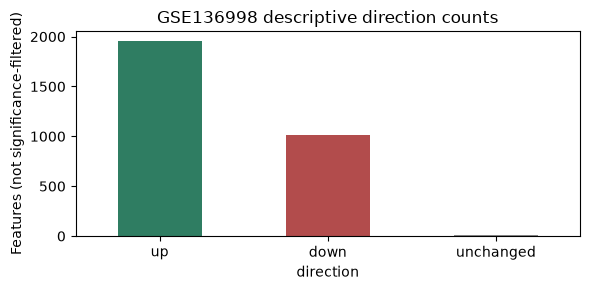

In [5]:
direction_counts = effects['direction'].value_counts().reindex(['up', 'down', 'unchanged'], fill_value=0)
display(direction_counts.rename('feature_count').to_frame())

top_up = effects.nlargest(15, 'log2_ratio_pseudocount_0.1')
top_down = effects.nsmallest(15, 'log2_ratio_pseudocount_0.1')
print('Largest descriptive increases')
display(top_up)
print('Largest descriptive decreases')
display(top_down)

ax = direction_counts.plot(kind='bar', color=['#2f7d62', '#b24c4c', '#888888'], figsize=(6, 3))
ax.set_ylabel('Features (not significance-filtered)')
ax.set_title('GSE136998 descriptive direction counts')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## Replicate consistency and expression distributions

Inspect log-transformed FPKM distributions and correlations before interpreting feature rankings. Correlation summarizes similarity of abundance profiles; it cannot establish biological replication or rule out batch confounding. The study design must support those claims independently. The figures are saved for use in the white paper.


,group,zero_features,median_fpkm,nonfinite_values
LM-DZ1,control,58,22.490,0
LM-DZ2,control,81,20.570,0
LM-DZ3,control,53,21.615,0
LM-FZC1,linalool_8h_1xMIC,105,40.550,0
LM-FZC2,linalool_8h_1xMIC,94,39.655,0
LM-FZC3,linalool_8h_1xMIC,146,38.350,0


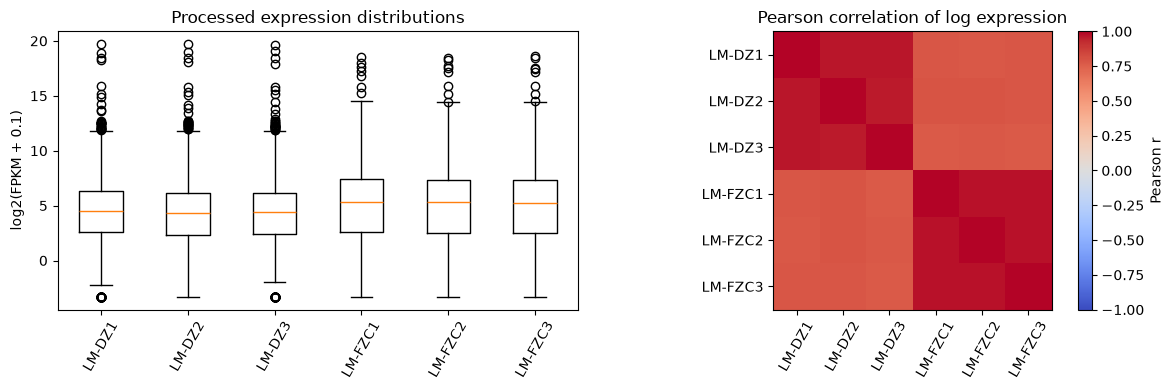

,LM-DZ1,LM-DZ2,LM-DZ3,LM-FZC1,LM-FZC2,LM-FZC3
LM-DZ1,1.000,0.966,0.964,0.782,0.781,0.782
LM-DZ2,0.966,1.000,0.958,0.793,0.792,0.789
LM-DZ3,0.964,0.958,1.000,0.771,0.774,0.769
LM-FZC1,0.782,0.793,0.771,1.000,0.976,0.972
LM-FZC2,0.781,0.792,0.774,0.976,1.000,0.970
LM-FZC3,0.782,0.789,0.769,0.972,0.970,1.000


In [6]:
FIGURES = PROJECT / 'results' / 'gse136998' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
log_expression = np.log2(expression + 0.1)
qc = pd.DataFrame({
    'group': metadata['group'],
    'zero_features': (expression == 0).sum(),
    'median_fpkm': expression.median(),
    'nonfinite_values': (~np.isfinite(expression)).sum(),
})
display(qc)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot([log_expression[s] for s in expression], tick_labels=expression.columns)
axes[0].tick_params(axis='x', rotation=60)
axes[0].set_ylabel('log2(FPKM + 0.1)')
axes[0].set_title('Processed expression distributions')
correlations = log_expression.corr()
im = axes[1].imshow(correlations, vmin=-1, vmax=1, cmap='coolwarm')
axes[1].set_xticks(range(6), expression.columns, rotation=60)
axes[1].set_yticks(range(6), expression.columns)
axes[1].set_title('Pearson correlation of log expression')
fig.colorbar(im, ax=axes[1], label='Pearson r')
fig.tight_layout()
fig.savefig(FIGURES / 'replicate_qc.png', dpi=180, bbox_inches='tight')
plt.show()
display(correlations.round(3))


## Abundance dependence and pseudocount sensitivity

A descriptive MA plot relates expression ratio to average abundance. Recalculate ratios with pseudocounts 0.01, 0.1 and 1 FPKM to inspect dependence on the arbitrary offset. The twofold threshold below is an exploratory magnitude threshold; it has no statistical significance interpretation. A low-expression flag is descriptive and does not define an inferential filtering rule.


,0.01,0.1,1.0,max_minus_min_log2_ratio,both_means_below_1_fpkm
gene_id,,,,,
rna10,-12.055734,-8.736853,-5.445042,6.610692,False
rna38,-12.055734,-8.736853,-5.445042,6.610692,False
rna72,-11.935165,-8.616549,-5.327328,6.607837,False
rna81,-11.935165,-8.616549,-5.327328,6.607837,False
rna69,-11.696823,-8.378801,-5.095362,6.601461,False
rna61,-10.523235,-7.210103,-3.973305,6.549930,False
rna55,-10.464205,-7.151439,-3.918068,6.546137,False
rna79,-9.921345,-6.612746,-3.417740,6.503605,False
rna12,-9.767633,-6.460524,-3.278976,6.488657,False


,pseudocount_fpkm,ratio_at_least_2,ratio_at_most_half
0,0.01,1324,579
1,0.10,1313,572
2,1.00,1249,466


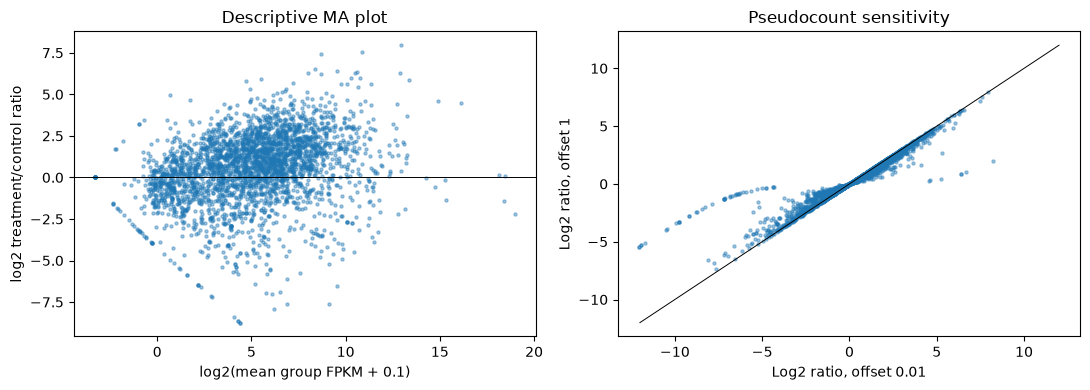

In [7]:
sensitivity = pd.DataFrame({
    str(offset): np.log2((treated_mean + offset) / (control_mean + offset))
    for offset in [0.01, 0.1, 1.0]
})
sensitivity['max_minus_min_log2_ratio'] = sensitivity.max(axis=1) - sensitivity.min(axis=1)
sensitivity['both_means_below_1_fpkm'] = (control_mean < 1) & (treated_mean < 1)
display(sensitivity.nlargest(15, 'max_minus_min_log2_ratio'))
summary = pd.DataFrame({
    'pseudocount_fpkm': [0.01, 0.1, 1.0],
    'ratio_at_least_2': [(sensitivity[str(x)] >= 1).sum() for x in [0.01, 0.1, 1.0]],
    'ratio_at_most_half': [(sensitivity[str(x)] <= -1).sum() for x in [0.01, 0.1, 1.0]],
})
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(np.log2((control_mean + treated_mean) / 2 + 0.1), sensitivity['0.1'], s=5, alpha=0.4)
axes[0].axhline(0, color='black', linewidth=0.7)
axes[0].set(xlabel='log2(mean group FPKM + 0.1)', ylabel='log2 treatment/control ratio', title='Descriptive MA plot')
axes[1].scatter(sensitivity['0.01'], sensitivity['1.0'], s=5, alpha=0.4)
lims = [-12, 12]
axes[1].plot(lims, lims, color='black', linewidth=0.7)
axes[1].set(xlabel='Log2 ratio, offset 0.01', ylabel='Log2 ratio, offset 1', title='Pseudocount sensitivity')
fig.tight_layout()
fig.savefig(FIGURES / 'ratio_sensitivity.png', dpi=180, bbox_inches='tight')
plt.show()
sensitivity.to_csv(DATA_DIR / 'pseudocount_sensitivity.tsv', sep='\t')
qc.to_csv(DATA_DIR / 'sample_qc.tsv', sep='\t')


## 5. Interpretation relative to the research question

This single contrast cannot answer which responses are reproducible because reproducibility requires independent studies/experiments with comparable compound identity, exposure, and context. It can establish a processing example and prioritize features for annotation and follow-up. The paper reports broad transcriptional changes after linalool exposure, but this notebook does not independently validate those pathways.

To distinguish general stress from compound- or target-specific biology, the next analysis should: (1) obtain raw counts or reads and annotation; (2) compare with other defined terpene exposures and organisms without pooling mixtures; (3) stratify by dose, time, strain, medium and viability; (4) compare pathway-level effects within species before cross-species orthology analysis; and (5) only use genetic perturbation/Perturb-seq datasets as a separate evidence layer for candidate dependencies. A matching genetic signature alone would not demonstrate direct binding or mediation.

## 6. Limitations and next steps

1. FPKM-only matrix: no valid count-based differential-expression inference in this notebook.
2. Three biological replicates per group and a single deposited timepoint.
3. Exposure is at the reported MIC, so cytotoxic/terminal stress may dominate.
4. GEO feature identifiers (`geneN`, `rnaN`) need a genome/annotation crosswalk.
5. No cell viability measurements are modeled here.
6. Microbial bulk RNA-seq does not establish mammalian signaling responses or demonstrate single-cell Perturb-seq expertise.
7. Results are not yet a Terpedia production ingestion; accession, compound identity, source checksum, method and evidence boundaries are preserved as a pilot.

### Reproduction

Install Jupyter, pandas, NumPy and Matplotlib in the desired environment, then launch this notebook from the project directory. The checked-in matrix and `run_manifest.json` are the frozen inputs; the checksum assertion verifies input identity. The companion script `../scripts/analyze_gse136998.py` generates the tabular descriptive summary from GEO.